In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob

In [10]:
sample_id = "3300060026"

df_umap_coords = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/comebin/comebin_res/umap_embeddings.tsv", 
    sep = '\t'
)

df_umap_coords['sample'] = sample_id
df_umap_coords.head()

,contig_id,umap_0,umap_1,sample
0,scaffold_1_c1,6.911039,3.650950,3300060026
1,scaffold_2_c1,9.473647,13.869589,3300060026
2,scaffold_5_c1,3.356064,-9.929160,3300060026
3,scaffold_6_c1,7.714851,6.510627,3300060026
4,scaffold_7_c1,6.848823,3.690145,3300060026


In [11]:
df_checkm = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/comebin_checkm/quality_report.tsv", 
    sep = '\t'
)

df_checkm[
    (df_checkm.Completeness > 50) & 
    (df_checkm.Contamination < 10)
].sort_values("Completeness", ascending = False)

,Name,Completeness,Contamination,Completeness_Model_Used,Translation_Table_Used,Coding_Density,Contig_N50,Average_Gene_Length,Genome_Size,GC_Content,Total_Coding_Sequences,Total_Contigs,Max_Contig_Length,Additional_Notes
128,26657,100.00,4.73,Gradient Boost (General Model),11,0.891,12582,276.073002,4290373,0.55,4630,496,56377,None
483,7920,99.79,1.88,Gradient Boost (General Model),11,0.919,25070,323.133526,2914491,0.64,2771,199,87546,None
36,14802,98.89,0.15,Neural Network (Specific Model),11,0.921,16629,302.727695,1058981,0.44,1076,98,70992,None
450,4733,96.67,1.72,Gradient Boost (General Model),11,0.860,38260,298.407711,2154055,0.52,2075,108,103708,None
542,17684,96.02,1.67,Gradient Boost (General Model),11,0.884,18558,298.360237,6130313,0.60,6071,544,64404,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,189966,52.14,4.00,Gradient Boost (General Model),11,0.896,5727,267.087673,2380475,0.59,2669,533,17261,None
548,183936,51.90,7.63,Gradient Boost (General Model),11,0.880,2881,225.421996,1883137,0.61,2455,738,17612,None
354,255673,51.49,0.27,Gradient Boost (General Model),11,0.928,2557,237.167837,2065558,0.63,2705,917,11559,None
46,161200,50.63,3.48,Gradient Boost (General Model),11,0.919,4080,263.681592,1725373,0.65,2010,521,19934,None


In [12]:
comebin_bins = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/comebin/comebin_res/comebin_res.tsv", 
    sep = '\t', 
    names = ['contig_id', 'group_id']
)

In [13]:
df = pd.merge(
    comebin_bins,
    df_umap_coords,
    on = 'contig_id'
)

In [14]:
df[['contig_id', 'group_id']].groupby('group_id').count().head()

,contig_id
group_id,
group0,1190
group1,1687
group10,1060
group100,831
group101,672




In [15]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'group_id', 
    alpha = 0.5
)

sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [16]:
! cat /gpfs/home/qcf21tku/scratch/E04_1/metabat_v1/bins_checked/eukcc.csv

cat: /gpfs/home/qcf21tku/scratch/E04_1/metabat_v1/bins_checked/eukcc.csv: No such file or directory


In [17]:
sample_id = "E04_1"

df_umap_coords = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/comebin_multi/comebin_res/umap_embeddings.tsv", 
    sep = '\t'
)

df_umap_coords['sample_id'] = df_umap_coords.contig_id.apply(lambda x: x.split("_")[0])
df_umap_coords.head()

,contig_id,umap_0,umap_1,sample_id
0,3300060270_Ga0586924_0000079,-3.368190,6.386423,3300060270
1,3300060270_Ga0586924_0000088,-3.347389,6.331737,3300060270
2,3300060270_Ga0586924_0000194,-3.376848,6.443119,3300060270
3,3300060270_Ga0586924_0000254,-3.353172,6.325690,3300060270
4,3300060270_Ga0586924_0000281,-3.392888,6.465913,3300060270


In [18]:
bins = pd.read_csv(
    f"/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/{sample_id}/comebin_multi/comebin_clusters/binning_res.tsv",
    sep = '\t', 
    names = ['contig_id', 'bin_id']
)

bins['bin_id'] = bins.bin_id.apply(lambda x: "comebin." + str(x))

In [19]:
df = pd.merge(
    df_umap_coords, 
    bins, 
    on = 'contig_id', 
    how = 'left'
).fillna("None")

df.head()

,contig_id,umap_0,umap_1,sample_id,bin_id
0,3300060270_Ga0586924_0000079,-3.368190,6.386423,3300060270,comebin.0
1,3300060270_Ga0586924_0000088,-3.347389,6.331737,3300060270,comebin.0
2,3300060270_Ga0586924_0000194,-3.376848,6.443119,3300060270,comebin.0
3,3300060270_Ga0586924_0000254,-3.353172,6.325690,3300060270,comebin.0
4,3300060270_Ga0586924_0000281,-3.392888,6.465913,3300060270,comebin.0


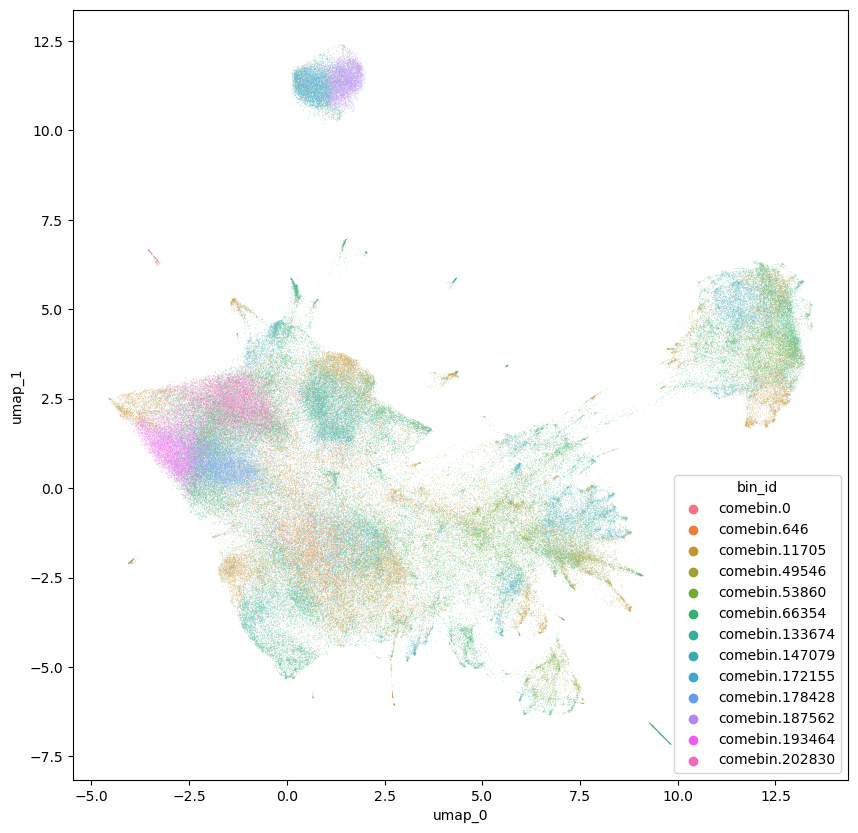

In [20]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'bin_id', 
    alpha = 0.5
)

In [21]:
! head /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_1/comebin_multi/comebin_coa/umap_embeddings.tsv

head: cannot open ‘/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_1/comebin_multi/comebin_coa/umap_embeddings.tsv’ for reading: No such file or directory


In [24]:
df_umap_v2 = pd.read_csv(
    "/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/E04_1/comebin_coa/comebin_res/umap_embeddings.tsv", 
    sep = '\t'
)

df_umap_v2.head()

,contig_id,umap_0,umap_1
0,k127_1786530,7.994836,-3.193965
1,k127_595511,7.535776,-3.187157
2,k127_1548328,9.319824,1.060218
3,k127_4883162,6.423035,2.234822
4,k127_5240467,10.032911,2.136727


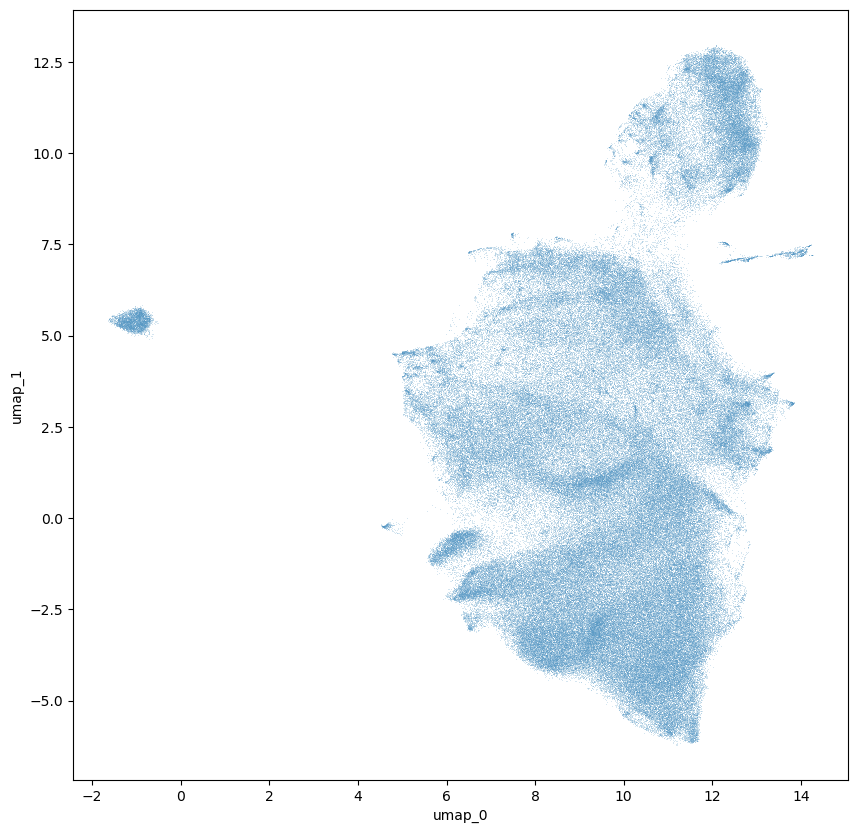

In [25]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df_umap_v2, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    #hue = 'sample_id', 
    alpha = 0.5
)

In [5]:
! realpath /gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300060027/comebin_test_v2_usepretrained/*

/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300060027/comebin_test_v2_usepretrained/embeddings.tsv
/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300060027/comebin_test_v2_usepretrained/umap_embeddings.tsv


In [6]:
df_umap_v3 = pd.read_csv(
    "/gpfs/data/mock_lab/will/mosaic_tmp/binning_dir/3300060027/comebin_test_v2_usepretrained/umap_embeddings.tsv", 
    sep = '\t'
)

df_umap_v3.head()

,contig_id,umap_0,umap_1
0,Ga0586926_0000001,10.474092,8.599774
1,Ga0586926_0000002,4.617442,6.462110
2,Ga0586926_0000003,10.576724,8.442765
3,Ga0586926_0000004,2.748410,9.628549
4,Ga0586926_0000005,3.327562,9.604817


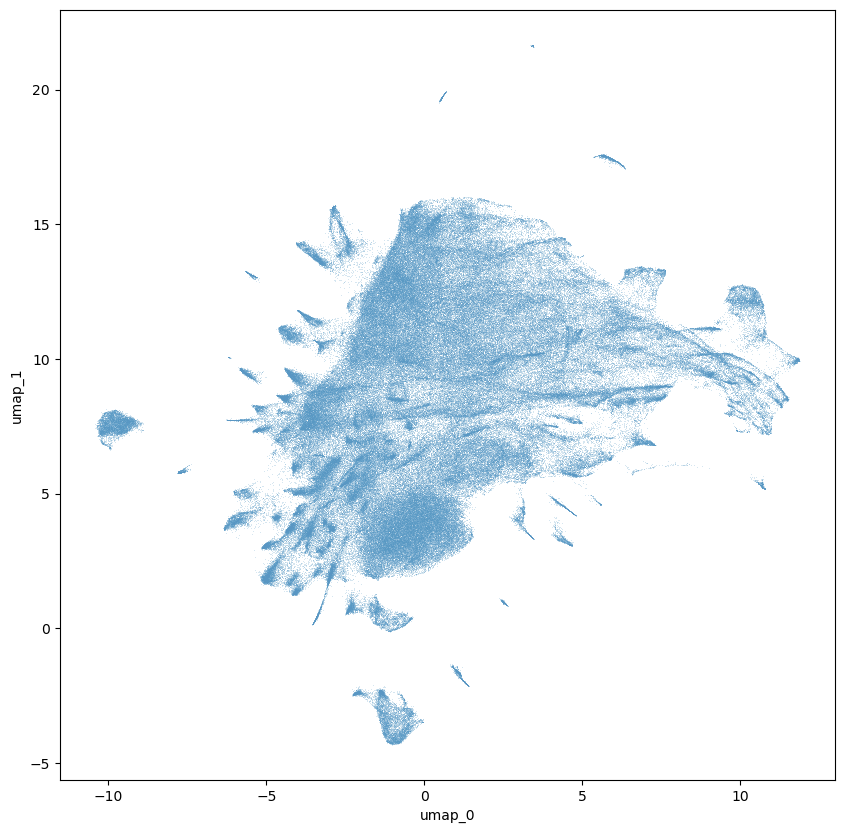

In [7]:
plt.figure(figsize = (10, 10))
ax = sns.scatterplot(
    data = df_umap_v3, 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    #hue = 'sample_id', 
    alpha = 0.5
)